In [1]:
# import libraries
import os
import pandas as pd
import numpy as np
import urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.cluster import MiniBatchKMeans
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve

In [2]:
# load dataset
file_name = "creditcard.csv"
file_id = "1ruS5aSUNLD0S7dcoO3vYlCoyMrHoeS1o"

download_url = f"https://drive.google.com/uc?id={file_id}"

if not os.path.exists(file_name):
    print("Downloading dataset from Google Drive...")
    !pip install -q gdown
    import gdown
    gdown.download(download_url, file_name, quiet=False)

df = pd.read_csv(file_name)
print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# check for shape
print(df.info())
print(df.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

the dataset has 284807 rows and 31 columns. It has datatypes float and int

In [4]:
# check for missing values
print("Missing values:", df.isnull().sum().sum())

Missing values: 0


there are no missing values

In [5]:
# check for duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1081


there are 1081 duplicated rows across the 31 columns

In [6]:
# size and imbalance
print(df["Class"].value_counts())


Class
0    284315
1       492
Name: count, dtype: int64


there are 492 fraud and 284315 normal.

In [7]:
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


fraud is about 0.173%.
A model that always predicts ‘not fraud’ would be 99.827% accurate, so accuracy is not a useful metric.”

In [8]:
# statistics
print(df[["Time", "Amount"]].describe())

                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000


the data is positively right skewed with mean of 88.35 and median of 22.00,standard dev is 250 which is almost thrice the mean. amount as a minimum of 0 value transactions.time spans betwen 0-172792 seconds.


# data preparation

In [9]:
dups = df[df.duplicated(keep=False)]
print("Rows involved in duplication:", len(dups))
print(dups["Class"].value_counts())
 
# handle duplicates
df_dedup = df.drop_duplicates()
print(df_dedup.shape)
print(df_dedup["Class"].value_counts())

Rows involved in duplication: 1854
Class
0    1822
1      32
Name: count, dtype: int64
(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


1081 dupliacted rows were dropped.a copy of each could land in both train and test sets causing data leakage and inflated scores. The duplicates removed 19 of 492 frauds which is about 3.9% compared 0.4% of normal rows and so 437 frauds remain.

In [10]:
df1 = df_dedup.copy()
df1.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [11]:
# transform Amount and  convert Time to hour
df1["LogAmount"] = np.log1p(df1["Amount"])
df1["Hour"] = (df1["Time"] // 3600) % 24

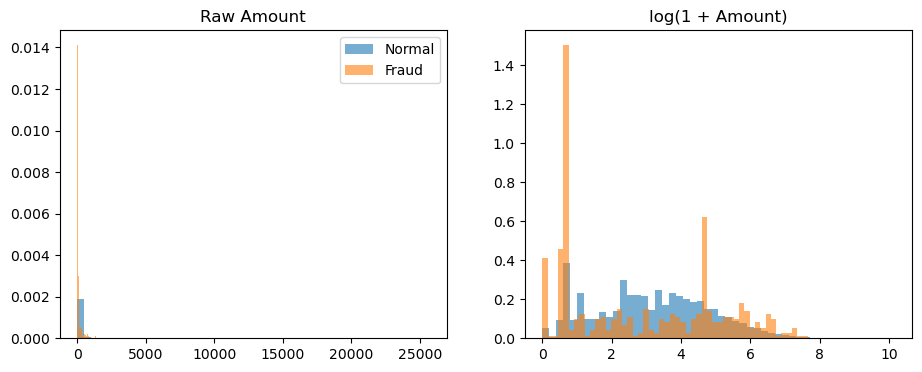

In [12]:
# Amount: raw vs log, by class
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c, label in [(0, "Normal"), (1, "Fraud")]:
    ax[0].hist(df1[df1.Class == c]["Amount"], bins=50, alpha=0.6, label=label, density=True)
    ax[1].hist(df1[df1.Class == c]["LogAmount"], bins=50, alpha=0.6, label=label, density=True)
ax[0].set_title("Raw Amount"); ax[1].set_title("log(1 + Amount)")
ax[0].legend(); plt.show()


Amount is heavily right skewed so log(1+x) elps reduce the influence of extreme values on distnace-based methods.

In [13]:
# Fraud rate by hour of day
print((df1.groupby("Hour")["Class"].mean() * 100).round(3))

Hour
0.0     0.078
1.0     0.238
2.0     1.451
3.0     0.488
4.0     1.044
5.0     0.368
6.0     0.220
7.0     0.318
8.0     0.088
9.0     0.101
10.0    0.048
11.0    0.316
12.0    0.111
13.0    0.111
14.0    0.139
15.0    0.159
16.0    0.134
17.0    0.174
18.0    0.165
19.0    0.122
20.0    0.108
21.0    0.091
22.0    0.059
23.0    0.156
Name: Class, dtype: float64


fraud rate varies widely by hour .It peaks at hours 2 to 5 which is upto 1.45%, about 9times the overall 0.167% and its lowest in te middle of the day .

In [14]:
# Which V features separate fraud from normal?
means = df1.groupby("Class")[[f"V{i}" for i in range(1, 29)]].mean().T
means["gap"] = (means[1] - means[0]).abs()
print(means.sort_values("gap", ascending=False).head(8))

Class         0         1       gap
V14    0.011668 -6.835946  6.847614
V3     0.012853 -6.729599  6.742452
V17    0.010963 -6.463285  6.474249
V12    0.009476 -6.103254  6.112730
V10    0.007663 -5.453274  5.460937
V7     0.010447 -5.175912  5.186359
V1     0.013439 -4.498280  4.511719
V4    -0.010440  4.472591  4.483031


V14 and V3 have the largest gap betwen fraud and normal averages.The separate Classes very well.

In [15]:
# split the data
X = df1.drop(columns=["Class", "Time", "Amount"])
y = df1["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

data is split by stratified split so both sets keep same fraud rate

In [16]:
# fit Scaler 
cols = ["LogAmount", "Hour"]
scaler = StandardScaler().fit(X_train[cols])
X_train[cols] = scaler.transform(X_train[cols])
X_test[cols] = scaler.transform(X_test[cols])

print("Train:", X_train.shape, "frauds:", y_train.sum(), f"({y_train.mean()*100:.3f}%)")
print("Test: ", X_test.shape, "frauds:", y_test.sum(), f"({y_test.mean()*100:.3f}%)")

Train: (198608, 30) frauds: 331 (0.167%)
Test:  (85118, 30) frauds: 142 (0.167%)


Training set was fitted with Scaler to prevent test set information from leaking into preprocessing.

# statistical outlier baseline

In [17]:
#  max |z-score|
mu = X_train.mean()
sd = X_train.std()
z_score = ((X_test - mu) / sd).abs().max(axis=1)

# Mahalanobis distance
cov_inv = np.linalg.pinv(np.cov(X_train.values, rowvar=False))
diff = X_test.values - mu.values
maha = np.sqrt(np.einsum("ij,jk,ik->i", diff, cov_inv, diff))

# Evaluation
def evaluate(name, score, y_true=y_test):
    order = np.argsort(-np.asarray(score))    
    y_sorted = np.asarray(y_true)[order]
    total = y_sorted.sum()
    out = {"AUPRC": average_precision_score(y_true, score),
           "ROC-AUC": roc_auc_score(y_true, score)}
    for k in (142, 500, 1000):               
        out[f"Prec@{k}"] = y_sorted[:k].mean()
        out[f"Recall@{k}"] = y_sorted[:k].sum() / total
    print(name, {k: round(v, 3) for k, v in out.items()})

evaluate("Max |z|   ", z_score)
evaluate("Mahalanobis", maha)
print("Random AUPRC would be about:", round(y_test.mean(), 4))

Max |z|    {'AUPRC': 0.085, 'ROC-AUC': 0.931, 'Prec@142': np.float64(0.155), 'Recall@142': np.float64(0.155), 'Prec@500': np.float64(0.104), 'Recall@500': np.float64(0.366), 'Prec@1000': np.float64(0.078), 'Recall@1000': np.float64(0.549)}
Mahalanobis {'AUPRC': 0.117, 'ROC-AUC': 0.947, 'Prec@142': np.float64(0.183), 'Recall@142': np.float64(0.183), 'Prec@500': np.float64(0.108), 'Recall@500': np.float64(0.38), 'Prec@1000': np.float64(0.084), 'Recall@1000': np.float64(0.592)}
Random AUPRC would be about: 0.0017


Mahalanobis distance beat the max |z-score| on every metric (AUPRC 0.117 vs 0.085; Precision@142 0.183 vs 0.155). A likely reason is that it accounts for correlations between features, while the z-score judges each feature alone. Both are far above random (AUPRC 0.0017), so they make a meaningful baseline. Precision@142 equals Recall@142 because the test set has 142 frauds.

# part 2

# k-means(cluster based approach)

In [18]:
results = {}
for k in (5, 10, 20, 40):
    km = MiniBatchKMeans(n_clusters=k, n_init=5, random_state=42, batch_size=4096)
    km.fit(X_train)                                  
    score = km.transform(X_test).min(axis=1)      
    results[k] = score
    evaluate(f"KMeans k={k:<2}", score)


KMeans k=5  {'AUPRC': 0.133, 'ROC-AUC': 0.947, 'Prec@142': np.float64(0.176), 'Recall@142': np.float64(0.176), 'Prec@500': np.float64(0.126), 'Recall@500': np.float64(0.444), 'Prec@1000': np.float64(0.088), 'Recall@1000': np.float64(0.62)}
KMeans k=10 {'AUPRC': 0.144, 'ROC-AUC': 0.954, 'Prec@142': np.float64(0.176), 'Recall@142': np.float64(0.176), 'Prec@500': np.float64(0.152), 'Recall@500': np.float64(0.535), 'Prec@1000': np.float64(0.094), 'Recall@1000': np.float64(0.662)}
KMeans k=20 {'AUPRC': 0.184, 'ROC-AUC': 0.956, 'Prec@142': np.float64(0.239), 'Recall@142': np.float64(0.239), 'Prec@500': np.float64(0.164), 'Recall@500': np.float64(0.577), 'Prec@1000': np.float64(0.109), 'Recall@1000': np.float64(0.768)}
KMeans k=40 {'AUPRC': 0.203, 'ROC-AUC': 0.955, 'Prec@142': np.float64(0.254), 'Recall@142': np.float64(0.254), 'Prec@500': np.float64(0.168), 'Recall@500': np.float64(0.592), 'Prec@1000': np.float64(0.113), 'Recall@1000': np.float64(0.796)}


Every k-means beats the statistical baseline.The best as k=40 has AUPRC of 0.203 which is about 1.7 times the mahalanobis baseline and roughly 120 times the random.perfomance rose steadily with k and the largest gain came between k=10 and k=20(+0.04);doubling to k=40 added only about 0.02 , suggesting dimininsing returns.
However the precision is still low.At k=40, precision@142 is 0.254 so about 3 in 4 of the top-ranked transactions are false alarms.

I choose cluster based method because it requires no labels and gives a simple score(distance to the nearest centroid).
normal spending most likely has many groups and more clusters describe them more tightly
however it missis fraud that looks normal and i chose k using the test set , so the best result is slightly optimistic.

# classification-based approach


In [ ]:
# Logistic regression with class weights
lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train, y_train)
evaluate("LogReg      ", lr.predict_proba(X_test)[:, 1])

# Random forest with class weights
rf = RandomForestClassifier(
    n_estimators=200, class_weight="balanced_subsample",
    min_samples_leaf=2, n_jobs=-1, random_state=42,
)
rf.fit(X_train, y_train)
evaluate("RandomForest", rf.predict_proba(X_test)[:, 1])

# Best unsupervised result for reference
evaluate("KMeans k=40 ", results[40])

LogReg       {'AUPRC': 0.692, 'ROC-AUC': 0.963, 'Prec@142': np.float64(0.782), 'Recall@142': np.float64(0.782), 'Prec@500': np.float64(0.238), 'Recall@500': np.float64(0.838), 'Prec@1000': np.float64(0.125), 'Recall@1000': np.float64(0.88)}


I choose clasiffication approach because labelled fraud exmaples exist and supervised models learn directly what separates fraud from normal.

I used class weights to handle the 0.167% imbalance and ranked transactions by predicted fraud probability.

Random forest was best(AUPRC 0.823,prec@142 0.817), ahead of logistic regression(0.692) and k-means (0.203)

Its limitation is that it only learns fraud patterns seen in training ,so new fraud types may be missed.

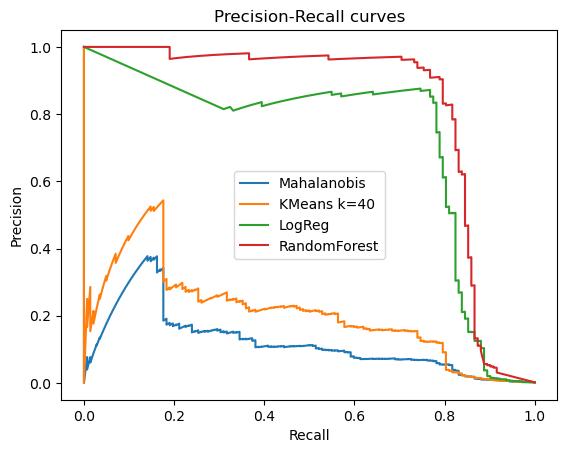

In [ ]:
# PR curves 
scores = {"Mahalanobis": maha, "KMeans k=40": results[40],
          "LogReg": lr.predict_proba(X_test)[:, 1],
          "RandomForest": rf.predict_proba(X_test)[:, 1]}
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    plt.plot(r, p, label=name)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.title("Precision-Recall curves")
plt.show()

Random forest keeps precision near 0.95 to 1.0 until recall reaches about 0.75, then drops sharply. Logistic regression follows a similar shape but with lower precision (about 0.82 to 0.88). K-means peaks at about 0.54 precision and Mahalanobis at about 0.37, then both fall below 0.25. ROC-AUC is similar across methods (0.93 to 0.96) while AUPRC ranges from 0.085 to 0.823, so AUPRC is the better metric for this imbalanced problem.

# Part 3

# why an unusual transaction is not necessarily fraudulent.

An anomaly detector measures rarity not fraud.Fraud is only one cause of unusal transactions.
Legitimate ones, such as a large one-off purchase, spending abroad or a holiday spike, can look just as odd.

My results show this. With the best unsupervised method (k-means, k=40), only about 36 of the top 142 flagged transactions (Precision@142 = 0.254) were fraud, so about 106 were unusual but legitimate. Because fraud is only 0.167% of transactions.Even Random forest which is precise in its top 142 (0.817),has precision of only 0.246 in its top 500, so about 377 of 500 flagged transactions are legitimate.

The reverse also holds. Fraud can look normal: Even the best model (random forest) missed about 13% of frauds in its top 1,000, and the unsupervised methods missed 20 to 45%.

Anomaly scores should therefore prioritise transactions for human review, not conclude fraud. The labelled classifier (random forest, Precision@142 = 0.817) did much better because it learned what fraud looks like, not just what is rare.

Hour is cyclical (hour 23 is next to hour 0), which StandardScaler does not capture. K was chosen on the test set, so the k-means result is slightly optimistic. The classifiers can only learn fraud patterns present in the training data.